## Processamento dos dados de valencia e ativação

Este notebook tem o proposito tem extrair os valores de valência e ativação de cada uma das emoções do dataset GoEmotions. Os valores serão extraidos dos léxico: https://saifmohammad.com/WebPages/nrc-vad.html

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

### 1. Carrega o arquivo do NRC VAD Lexicon (separado por tabulação)

In [15]:
emotions_values_path = Path("../data/raw/NRC-VAD-Lexicon-v2.1.txt")
emotions_values_df = pd.read_csv(emotions_values_path, sep=r"\t", engine="python")
emotions_values_df.head()

,term,valence,arousal,dominance
0,a battery,0.134,-0.298,-0.096
1,a bit,-0.096,-0.264,-0.214
2,a bunch,0.088,-0.350,-0.068
3,a cappella,0.134,-0.116,-0.200
4,a couple,0.266,-0.110,0.090


### 2. Lista das 27 emoções do GoEmotions em inglês

In [16]:
emocoes_goemotions = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring',
    'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval',
    'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief',
    'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization',
    'relief', 'remorse', 'sadness', 'surprise'
]

### 3. Filtra pelas 27 emoções do dataset GoEmotions

In [27]:
emotions_values_df = emotions_values_df[emotions_values_df['term'].isin(emocoes_goemotions)].drop(columns=['dominance'])
print(emotions_values_df)

                 term  valence  arousal
626        admiration    0.938    0.166
1526        amusement    0.858    0.674
1656            anger   -0.666    0.730
1733        annoyance   -0.666    0.436
2175         approval    0.708   -0.080
6856           caring    0.270   -0.062
9483        confusion   -0.490    0.334
11218       curiosity    0.500    0.510
12590          desire    0.792    0.384
13207  disappointment   -0.770   -0.020
13208     disapproval   -0.830    0.102
13425         disgust   -0.896    0.550
15345   embarrassment   -0.714    0.370
16405      excitement    0.792    0.368
17413            fear   -0.854    0.680
20955       gratitude    0.770   -0.118
21103           grief   -0.860    0.280
26738             joy    0.960    0.648
28790            love    0.996    0.334
32018     nervousness   -0.674    0.830
33706        optimism    0.898    0.130
37520           pride    0.458    0.268
39182     realization    0.108    0.020
39947          relief    0.688   -0.444


### 4. Adicionando a categoria neutra

In [30]:
### adicionando o valor neutro com valores 0 e 0
emotions_values_df = pd.concat([emotions_values_df, pd.DataFrame({'term': ['neutro'], 'valence': [0], 'arousal': [0]})], ignore_index=True)
emotions_values_df.head(28)

,term,valence,arousal
0,admiration,0.938,0.166
1,amusement,0.858,0.674
2,anger,-0.666,0.730
3,annoyance,-0.666,0.436
4,approval,0.708,-0.080
5,caring,0.270,-0.062
6,confusion,-0.490,0.334
7,curiosity,0.500,0.510
8,desire,0.792,0.384
9,disappointment,-0.770,-0.020


### 5. Criando uma imagem com cada emoção no espaço dimensional de Russell

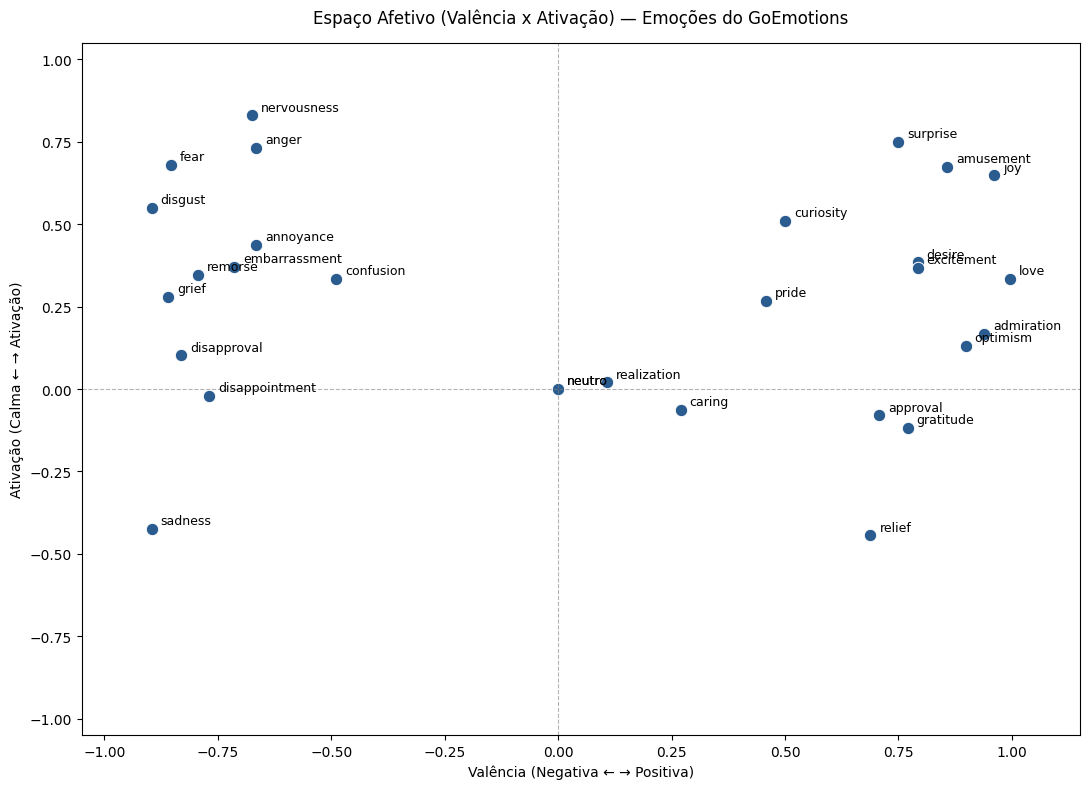

In [31]:
plt.figure(figsize=(11, 8))

# Plota os pontos
ax = sns.scatterplot(
    data=emotions_values_df,
    x="valence",
    y="arousal",
    s=80,
    color="#2b5c8f"
)

# Linhas centrais para dividir os 4 quadrantes afetivos
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.6)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.6)

# Adiciona o nome de cada emoção ao lado do ponto
for _, row in emotions_values_df.iterrows():
    ax.text(
        row["valence"] + 0.02,
        row["arousal"] + 0.015,
        row["term"],
        fontsize=9
    )

plt.title("Espaço Afetivo (Valência x Ativação) — Emoções do GoEmotions", pad=14)
plt.xlabel("Valência (Negativa ← → Positiva)")
plt.ylabel("Ativação (Calma ← → Ativação)")
plt.xlim(-1.05, 1.15)
plt.ylim(-1.05, 1.05)
plt.tight_layout()
plt.show()

### 6. Salvando os dados processados

In [32]:
emotions_values_df.to_csv("../data/processed/emotions_values.csv", index=False)